# New Dataset – Step 4: Which Approach is Best?

In the old data, two prompting approaches (Holistic vs. Linguistic) were compared in
`Linguistic_Vs_Holistic_Approach_GPT_4_0.ipynb` with a **paired test**:
Shapiro–Wilk on the differences → **paired t-test** (normal) or **Wilcoxon signed-rank test** (not normal).

Here there are **3 approaches**, so:
1. **Friedman test** over the 3 approaches (+ Kendall's W)
2. **Pairwise paired tests** (Shapiro → t-test / Wilcoxon, same as the old notebook) with **Bonferroni** correction (3 pairs)
3. Winner per metric (lower = better, except FRE)

This is done per model (n = 10 texts) and for **all models pooled** (n = 40 = 4 models × 10 texts).

After that:
* **Change vs. Original** – how much each approach simplified compared with the official German source text
* **Overall ranking of all 12 model + approach combinations**

| Name | Pipeline |
|---|---|
| **Original** | official German source text (`Source_Texts_German`, human, same for all models) |
| **Approach_1** | English → English Easy → German Easy |
| **Approach_2** | English → standard German → German Easy |
| **Approach_3** | English → German Easy (direct) |

Scores come from `New_dataset_1_Metric_Scores.ipynb` (`New dataset/<model>/Matrix_Scores_<model>.csv`).

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from scipy.stats import friedmanchisquare, wilcoxon
from itertools import combinations
from statsmodels.stats.multitest import multipletests

DATA_DIR = "New dataset"
RESULTS_DIR = os.path.join(DATA_DIR, "results")
os.makedirs(RESULTS_DIR, exist_ok=True)

# Short name -> folder name
MODELS = {
    "DeepSeek-V4-Flash": "deepseek-v4-flash-0731",
    "Gemma-4-31B":       "gemma-4-31b-it",
    "Llama-3.1-8B":      "meta-llama-3.1-8b-instruct",
    "Qwen3.5-397B":      "qwen3.5-397b-a17b",
}
APPROACHES = ["Approach_1", "Approach_2", "Approach_3"]

METRICS = ["TTR", "LD", "WR", "MDD", "SI", "Cross", "WSF", "LIX", "FRE", "Fog"]
LEXICAL_METRICS = ["TTR", "LD", "WR"]
SYNTACTIC_METRICS = ["MDD", "SI", "Cross"]
READABILITY_METRICS = ["WSF", "LIX", "FRE", "Fog"]

# Direction (as defined in the paper): lower = better for all metrics except FRE
HIGHER_BETTER = ["FRE"]

MODEL_COLORS = {
    "Original":          "#7f7f7f",
    "DeepSeek-V4-Flash": "#1f77b4",
    "Gemma-4-31B":       "#ff7f0e",
    "Llama-3.1-8B":      "#2ca02c",
    "Qwen3.5-397B":      "#d62728",
}
APPROACH_COLORS = {"Original": "#7f7f7f", "Approach_1": "#8dd3c7", "Approach_2": "#fdb462", "Approach_3": "#bebada"}

scores = {
    name: pd.read_csv(os.path.join(DATA_DIR, folder, f"Matrix_Scores_{folder}.csv")).sort_values("ID").reset_index(drop=True)
    for name, folder in MODELS.items()
}

# All models must contain the same texts in the same order (paired tests)
for df in scores.values():
    assert list(df["ID"]) == list(scores["Qwen3.5-397B"]["ID"])

In [2]:
# Same paired test as in Linguistic_Vs_Holistic_Approach_GPT_4_0.ipynb
def compare_columns(col1, col2):
    diff = col1 - col2
    if np.allclose(diff, 0):
        return np.nan, 1.0, 0.0, "identical"

    shapiro_p = stats.shapiro(diff).pvalue
    if shapiro_p > 0.05:
        p_val = stats.ttest_rel(col1, col2).pvalue
        effect = diff.mean() / np.std(diff, ddof=1)                      # Cohen's d (paired)
        test = "t-test"
    else:
        p_val = stats.wilcoxon(col1, col2).pvalue
        effect = (np.sum(diff > 0) - np.sum(diff < 0)) / len(diff)       # rank-biserial (simple)
        test = "Wilcoxon"
    return shapiro_p, p_val, effect, test


def is_better(metric, a, b):
    return a > b if metric in HIGHER_BETTER else a < b


def compare_approaches(df):
    wins_all = {a: 0 for a in APPROACHES}
    wins_significant = {a: 0 for a in APPROACHES}
    rows = []

    for metric in METRICS:
        tmp = pd.DataFrame({a: df[f"{metric}_{a}"].astype(float).values for a in APPROACHES})
        n, k = tmp.shape

        stat, p_friedman = stats.friedmanchisquare(*[tmp[a] for a in APPROACHES])
        W = stat / (n * (k - 1))

        means = tmp.mean()
        best = means.idxmax() if metric in HIGHER_BETTER else means.idxmin()
        wins_all[best] += 1

        # Pairwise paired tests + Bonferroni
        pairs = list(combinations(APPROACHES, 2))
        pair_results = [compare_columns(tmp[a], tmp[b]) for a, b in pairs]
        adj_p = multipletests([r[1] for r in pair_results], method="bonferroni")[1]

        significant_pairs = []
        for (a, b), r, p in zip(pairs, pair_results, adj_p):
            if p_friedman < 0.05 and p < 0.05:
                better = a if is_better(metric, means[a], means[b]) else b
                worse = b if better == a else a
                significant_pairs.append((better, worse, p, r[3]))

        winner_beats = [w for b, w, p, t in significant_pairs if b == best]
        if winner_beats:
            wins_significant[best] += 1

        row = {"Metric": metric, "n": n}
        for a in APPROACHES:
            row[f"{a}_mean"] = round(means[a], 3)
        row.update({
            "Friedman_p": round(p_friedman, 6),
            "Kendalls_W": round(W, 4),
            "Winner": best,
            "Winner_better_than": ", ".join(winner_beats) if winner_beats else "–",
            "Significant_pairs": "; ".join(f"{b} vs {w} (p={p:.3f}, {t})" for b, w, p, t in significant_pairs) or "–",
        })
        rows.append(row)

    return pd.DataFrame(rows), wins_all, wins_significant

## Approach comparison per model (n = 10)

In [3]:
pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 20)
pd.set_option("display.max_colwidth", 90)

approach_wins = {}
approach_wins_sig = {}

for model, df in scores.items():
    res, wins_all, wins_sig = compare_approaches(df)
    approach_wins[model] = wins_all
    approach_wins_sig[model] = wins_sig
    print(f"\n======================= {model} =======================")
    print(res.to_string(index=False))
    print("Total wins (descriptive):", wins_all)
    print("Significant wins:        ", wins_sig)
    res.to_csv(os.path.join(RESULTS_DIR, f"Approach_Comparison_{MODELS[model]}.csv"), index=False)


======================= DeepSeek-V4-Flash =======================
Metric  n  Approach_1_mean  Approach_2_mean  Approach_3_mean  Friedman_p  Kendalls_W     Winner     Winner_better_than                                                                        Significant_pairs
   TTR 10            0.448            0.490            0.481    0.406570      0.0900 Approach_1                      –                                                                                        –
    LD 10            0.481            0.487            0.487    0.272532      0.1300 Approach_1                      –                                                                                        –
    WR 10            0.046            0.046            0.057    0.272532      0.1300 Approach_2                      –                                                                                        –
   MDD 10            2.425            1.989            2.263    0.000112      0.9100 Approach_2 Appro


======================= Llama-3.1-8B =======================
Metric  n  Approach_1_mean  Approach_2_mean  Approach_3_mean  Friedman_p  Kendalls_W     Winner     Winner_better_than                                                                      Significant_pairs
   TTR 10            0.466            0.493            0.474    0.209276      0.1564 Approach_1                      –                                                                                      –
    LD 10            0.483            0.495            0.486    0.496585      0.0700 Approach_1                      –                                                                                      –
    WR 10            0.050            0.087            0.086    0.001836      0.6300 Approach_1 Approach_2, Approach_3 Approach_1 vs Approach_2 (p=0.008, t-test); Approach_1 vs Approach_3 (p=0.006, t-test)
   MDD 10            2.722            3.247            3.342    0.000225      0.8400 Approach_1 Approach_2, Approa

## All models pooled (n = 40)

In [4]:
pooled = pd.concat(scores.values(), ignore_index=True)
pooled_res, pooled_wins, pooled_wins_sig = compare_approaches(pooled)
print(pooled_res.to_string(index=False))
print("\nTotal wins (descriptive):", pooled_wins)
print("Significant wins:        ", pooled_wins_sig)
pooled_res.to_csv(os.path.join(RESULTS_DIR, "Approach_Comparison_All_Models.csv"), index=False)

# Without Llama-3.1-8B (its Approach_2 / Approach_3 outputs are almost unchanged standard German, see below)
pooled_no_llama = pd.concat([df for m, df in scores.items() if m != "Llama-3.1-8B"], ignore_index=True)
res_no_llama, wins_no_llama, wins_sig_no_llama = compare_approaches(pooled_no_llama)
print("\n---------- Without Llama-3.1-8B (n = 30) ----------")
print(res_no_llama.to_string(index=False))
print("\nTotal wins (descriptive):", wins_no_llama)
print("Significant wins:        ", wins_sig_no_llama)

Metric  n  Approach_1_mean  Approach_2_mean  Approach_3_mean  Friedman_p  Kendalls_W     Winner     Winner_better_than                                                                          Significant_pairs
   TTR 40            0.469            0.494            0.497    0.007546      0.1222 Approach_1 Approach_2, Approach_3     Approach_1 vs Approach_2 (p=0.031, t-test); Approach_1 vs Approach_3 (p=0.017, t-test)
    LD 40            0.485            0.491            0.486    0.150607      0.0473 Approach_1                      –                                                                                          –
    WR 40            0.038            0.048            0.050    0.149276      0.0475 Approach_1                      –                                                                                          –
   MDD 40            2.188            2.233            2.345    0.007447      0.1225 Approach_1             Approach_3 Approach_1 vs Approach_3 (p=0.045, Wilcox

In [5]:
approach_summary = pd.concat({
    "Wins": pd.DataFrame(approach_wins | {"All models": pooled_wins, "All without Llama": wins_no_llama}),
    "Significant wins": pd.DataFrame(approach_wins_sig | {"All models": pooled_wins_sig, "All without Llama": wins_sig_no_llama}),
}, axis=0)
approach_summary.to_csv(os.path.join(RESULTS_DIR, "Approach_Comparison_Wins.csv"))
approach_summary

DeepSeek-V4-Flash  Gemma-4-31B  Llama-3.1-8B  Qwen3.5-397B  All models  All without Llama
Wins             Approach_1                  2           10             9             7           8                  3
                 Approach_2                  8            0             1             0           1                  6
                 Approach_3                  0            0             0             3           1                  1
Significant wins Approach_1                  0            0             6             0           6                  1
                 Approach_2                  2            0             0             0           0                  1
                 Approach_3                  0            0             0             0           0                  0

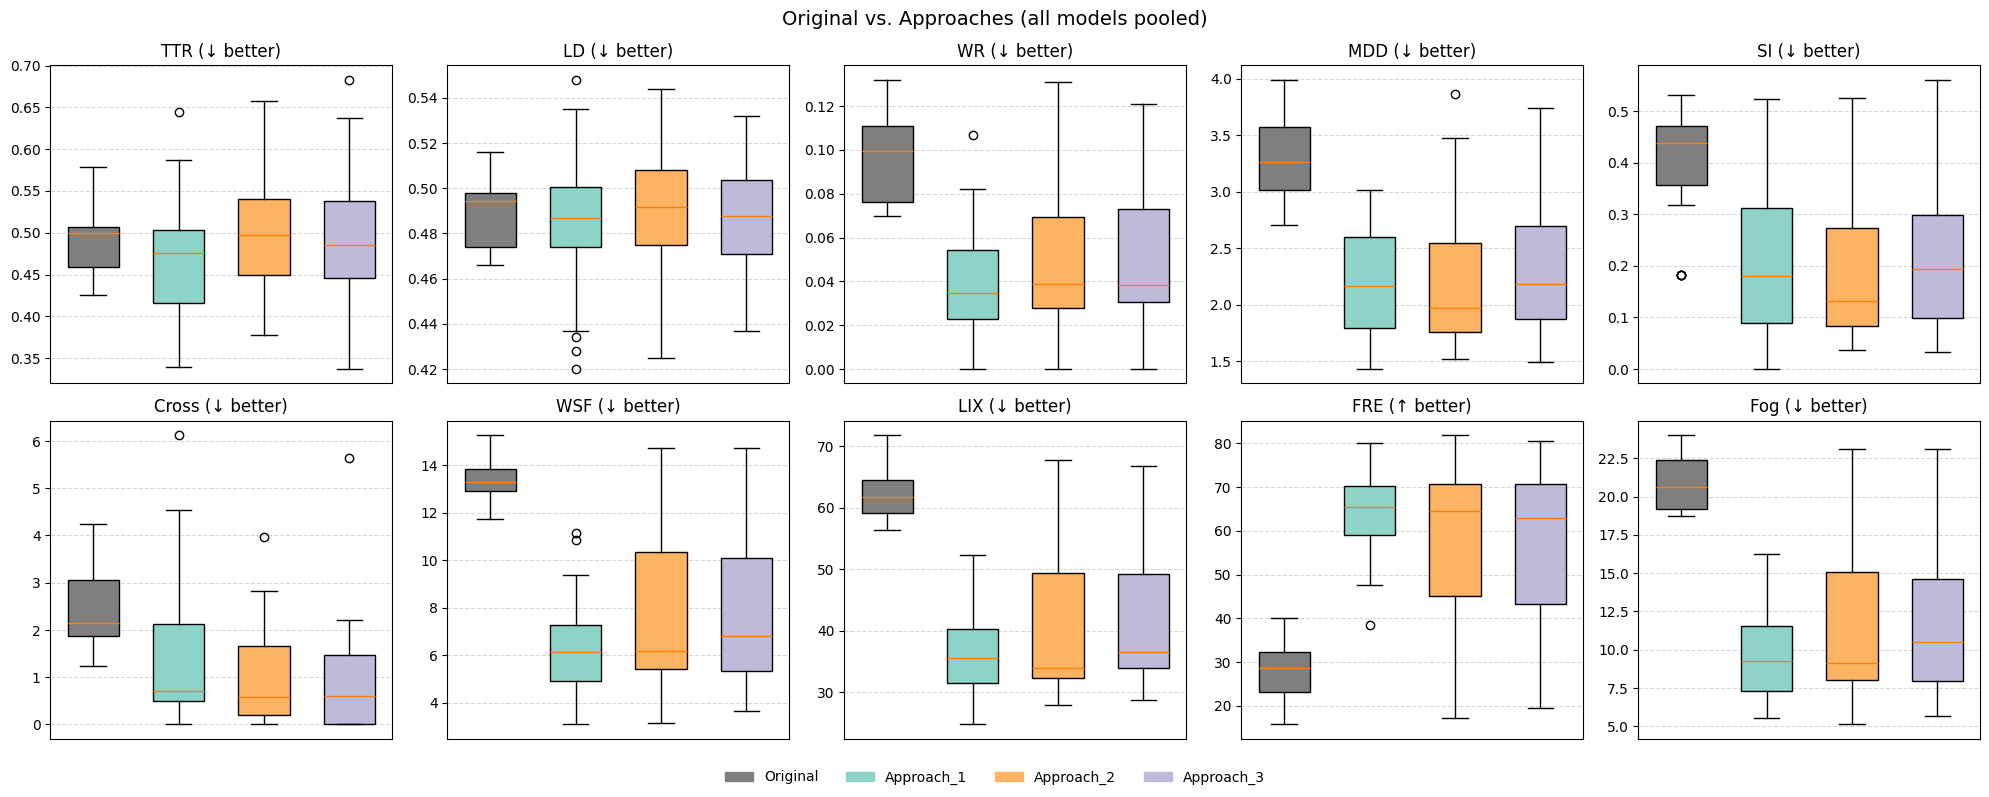

In [6]:
def plot_approaches(df, title, file_name):
    fig, axes = plt.subplots(2, 5, figsize=(20, 8))
    axes = axes.flatten()
    versions = ["Original"] + APPROACHES

    for ax, metric in zip(axes, METRICS):
        data = [df[f"{metric}_{v}"] for v in versions]
        box = ax.boxplot(data, patch_artist=True, widths=0.6)
        for patch, v in zip(box["boxes"], versions):
            patch.set_facecolor(APPROACH_COLORS[v])
        direction = "↑" if metric in HIGHER_BETTER else "↓"
        ax.set_title(f"{metric} ({direction} better)")
        ax.set_xticks([])
        ax.grid(axis="y", linestyle="--", alpha=0.5)

    handles = [plt.Rectangle((0, 0), 1, 1, color=APPROACH_COLORS[v]) for v in versions]
    fig.legend(handles, versions, loc="lower center", ncol=4, frameon=False)
    fig.suptitle(title, fontsize=14)
    plt.tight_layout(rect=[0, 0.05, 1, 1])
    plt.savefig(os.path.join(RESULTS_DIR, file_name), dpi=150)
    plt.show()


plot_approaches(pooled, "Original vs. Approaches (all models pooled)", "Approach_Comparison_All_Models.png")

## Change vs. Original

How much did each approach simplify the standard German translation?
`Δ% = (Approach − Original) / Original × 100` (negative = lower value).
**Improved** = number of metrics (out of 10) that moved in the "better" direction.

In [7]:
change_rows = []
for model, df in scores.items():
    for a in APPROACHES:
        row = {"Model": model, "Approach": a}
        improved = 0
        for metric in METRICS:
            orig = df[f"{metric}_Original"].mean()
            new = df[f"{metric}_{a}"].mean()
            row[metric] = round((new - orig) / orig * 100, 1)
            improved += is_better(metric, new, orig)
        row["Improved"] = improved
        change_rows.append(row)

change_df = pd.DataFrame(change_rows)
change_df.to_csv(os.path.join(RESULTS_DIR, "Change_vs_Original.csv"), index=False)
change_df

,Model,Approach,TTR,LD,WR,MDD,SI,Cross,WSF,LIX,FRE,Fog,Improved
0,DeepSeek-V4-Flash,Approach_1,-8.5,-1.8,-53.0,-26.5,-34.7,-40.6,-44.8,-34.4,118.3,-48.4,10
1,DeepSeek-V4-Flash,Approach_2,-0.1,-0.4,-53.2,-39.7,-70.2,-72.7,-49.4,-40.2,128.4,-54.3,10
2,DeepSeek-V4-Flash,Approach_3,-1.9,-0.6,-41.2,-31.4,-50.9,-67.0,-41.1,-33.5,110.5,-47.2,10
3,Gemma-4-31B,Approach_1,10.0,-1.1,-70.6,-40.4,-64.7,-73.2,-61.5,-48.5,152.9,-61.4,9
4,Gemma-4-31B,Approach_2,13.7,-0.4,-70.0,-38.7,-59.5,-62.7,-58.9,-46.5,148.7,-58.7,9
5,Gemma-4-31B,Approach_3,19.0,-1.0,-67.0,-37.1,-60.7,-69.3,-58.5,-46.0,150.9,-58.7,9
6,Llama-3.1-8B,Approach_1,-4.8,-1.4,-48.5,-17.6,-4.2,11.6,-40.7,-31.9,102.4,-42.6,9
7,Llama-3.1-8B,Approach_2,0.6,1.0,-10.9,-1.6,2.0,-24.2,-0.9,-2.7,4.2,-3.4,7
8,Llama-3.1-8B,Approach_3,-3.3,-0.8,-11.3,1.2,8.3,-16.1,-0.9,-1.2,6.8,-1.2,8
9,Qwen3.5-397B,Approach_1,-13.9,0.7,-72.2,-50.4,-89.8,-83.6,-62.4,-50.0,158.3,-63.8,9


## Overall ranking: best model + approach combination

For every metric, the 12 combinations (4 models × 3 approaches) are ranked by their mean (1 = best).
The final score is the **mean rank** over the 10 metrics (and per metric group).

In [8]:
combo_means = {}
for model, df in scores.items():
    for a in APPROACHES:
        combo_means[f"{model} | {a}"] = {m: df[f"{m}_{a}"].mean() for m in METRICS}
combo_means = pd.DataFrame(combo_means).T

combo_ranks = pd.DataFrame({
    m: combo_means[m].rank(ascending=m not in HIGHER_BETTER) for m in METRICS
})

ranking = pd.DataFrame({
    "Lexical_rank": combo_ranks[LEXICAL_METRICS].mean(axis=1),
    "Syntactic_rank": combo_ranks[SYNTACTIC_METRICS].mean(axis=1),
    "Readability_rank": combo_ranks[READABILITY_METRICS].mean(axis=1),
    "Mean_rank": combo_ranks.mean(axis=1),
}).round(2).sort_values("Mean_rank")

ranking.to_csv(os.path.join(RESULTS_DIR, "Overall_Ranking_Model_Approach.csv"))
ranking

,Lexical_rank,Syntactic_rank,Readability_rank,Mean_rank
Qwen3.5-397B | Approach_1,4.33,1.33,1.00,2.1
Qwen3.5-397B | Approach_2,6.33,2.33,2.25,3.5
Qwen3.5-397B | Approach_3,4.67,2.33,3.75,3.6
Gemma-4-31B | Approach_1,5.33,4.33,3.00,4.1
Gemma-4-31B | Approach_3,7.33,6.33,5.50,6.3
DeepSeek-V4-Flash | Approach_2,7.33,4.67,7.00,6.4
Gemma-4-31B | Approach_2,7.67,7.00,5.50,6.6
DeepSeek-V4-Flash | Approach_1,4.00,9.00,8.00,7.1
DeepSeek-V4-Flash | Approach_3,7.67,7.67,9.00,8.2
Llama-3.1-8B | Approach_1,5.33,10.67,10.00,8.8


In [9]:
# Mean rank per approach (averaged over models) and per model (averaged over approaches)
rank_by = ranking.copy()
rank_by["Model"] = [i.split(" | ")[0] for i in rank_by.index]
rank_by["Approach"] = [i.split(" | ")[1] for i in rank_by.index]

print("------ Mean rank per approach ------")
print(rank_by.groupby("Approach")[["Lexical_rank", "Syntactic_rank", "Readability_rank", "Mean_rank"]].mean().round(2).sort_values("Mean_rank"))
print("\n------ Mean rank per model ------")
print(rank_by.groupby("Model")[["Lexical_rank", "Syntactic_rank", "Readability_rank", "Mean_rank"]].mean().round(2).sort_values("Mean_rank"))

------ Mean rank per approach ------
            Lexical_rank  Syntactic_rank  Readability_rank  Mean_rank
Approach                                                             
Approach_1          4.75            6.33               5.5       5.52
Approach_2          8.00            6.17               6.5       6.85
Approach_3          6.75            7.00               7.5       7.12

------ Mean rank per model ------
                   Lexical_rank  Syntactic_rank  Readability_rank  Mean_rank
Model                                                                       
Qwen3.5-397B               5.11            2.00              2.33       3.07
Gemma-4-31B                6.78            5.89              4.67       5.67
DeepSeek-V4-Flash          6.33            7.11              8.00       7.23
Llama-3.1-8B               7.78           11.00             11.00      10.03


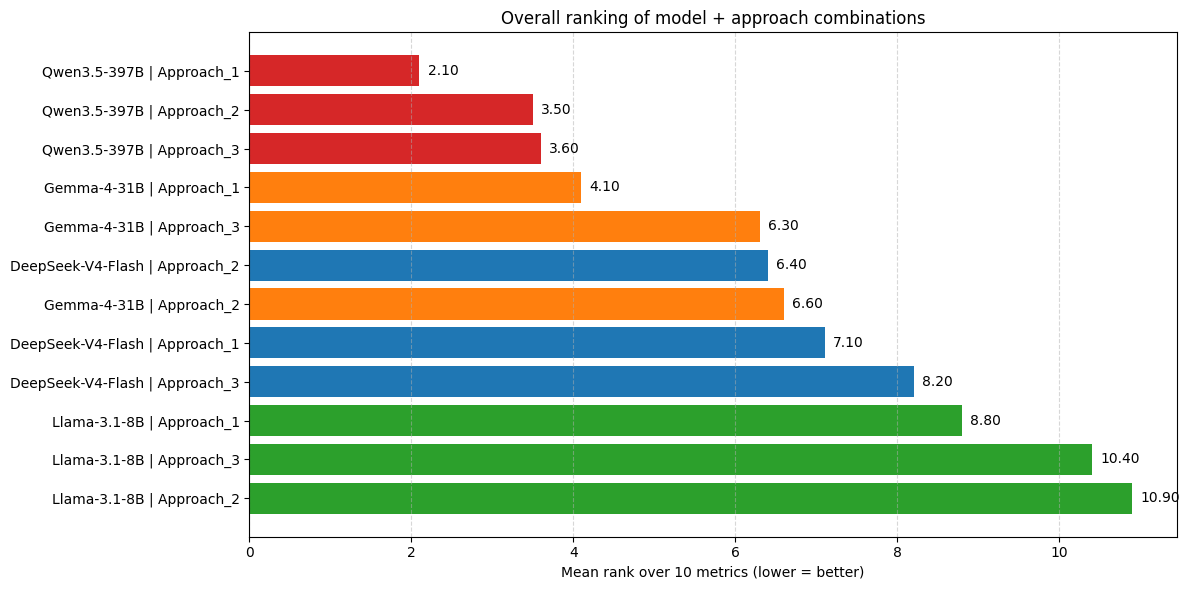

In [10]:
fig, ax = plt.subplots(figsize=(12, 6))
colors = [MODEL_COLORS[i.split(" | ")[0]] for i in ranking.index]
ax.barh(ranking.index[::-1], ranking["Mean_rank"][::-1], color=colors[::-1])
for y, v in enumerate(ranking["Mean_rank"][::-1]):
    ax.text(v + 0.1, y, f"{v:.2f}", va="center")
ax.set_xlabel("Mean rank over 10 metrics (lower = better)")
ax.set_title("Overall ranking of model + approach combinations")
ax.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "Overall_Ranking_Model_Approach.png"), dpi=150)
plt.show()

## Findings – which approach is best?

* **Every approach simplifies the text strongly** compared with the official German source text, for DeepSeek, Gemma and Qwen:
  * LIX goes down by about 33–50 %
  * FRE more than doubles (+110 to +158 %)
  * SI goes down by 35–90 %
* The exception is **Llama-3.1-8B**. Its Approach_2 / Approach_3 outputs barely change the readability scores (≈ 1–7 %), and in Approach_3 SI even goes up (+8 %).
* **All models pooled (n = 40): Approach_1 (English → English Easy → German Easy) is the best approach.**
  * It wins 8 of 10 metrics, and 6 of those wins are significant.
  * It is significantly better than Approach_3 on MDD, WSF, LIX, FRE and Fog.
  * It also has the best mean rank (5.52, vs. 6.85 for Approach_2 and 7.12 for Approach_3).
* However, much of this advantage comes from **Llama-3.1-8B**: Approach_1 is the only approach where Llama simplifies at all.
  * Without Llama (n = 30), the three approaches are very close and almost nothing is significant.
  * Approach_2 has the most descriptive wins (6/10) and is significantly better than Approach_3 on MDD.
  * Approach_1 is significantly better than Approach_3 on TTR.
* Per model:
  * **Qwen and Gemma:** Approach_1 is best descriptively (7/10 and 10/10 wins), but not significantly.
  * **DeepSeek:** Approach_2 is best, significantly better on MDD and SI.
  * **Llama:** Approach_1 is best, with 6 significant wins.
* **Approach_3 (direct)** is never significantly the best and is usually the weakest.
* **Best combination overall: Qwen3.5-397B + Approach_1** (mean rank 2.1 of 12), followed by Qwen + Approach_2 and Qwen + Approach_3.

**Conclusion:**
* The **model** matters much more than the **approach**.
* Among the approaches, the two-step pipelines (Approach_1, Approach_2) are at least as good as direct translation into Easy German, and Approach_1 is the safest choice, because it also works for weak models.

⚠️ Approach_1 goes through English Easy Language, so information may be lost twice. Content correctness is not measured by these metrics and should be checked manually.
